In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(3)

20

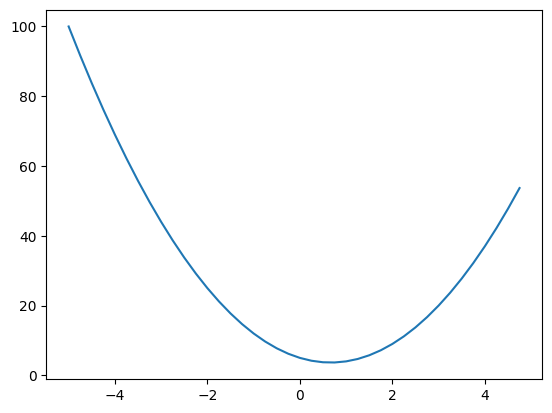

In [ ]:
xs = np.arange(-5, 5, 0.25)  # arange(시작, 끝, 간격) 함수를 사용해 -5부터 5 미만까지 0.25 간격으로 숫자를 생성
ys = f(xs) # 미리 정의된 함수 f에 x배열(xs)을 전달하여 각 x에 대응하는 y 값들의 배열을 구함
plt.plot(xs, ys)  # 각 $(x, y)$ 좌표점들을 순서대로 선으로 연결한 2D 선 그래프(Line plot)를 생성


In [22]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0  # 현재 Value data가 1증가 할 때, 최종 output L이 얼마나 증가하는지에 대한 값
        self._backward = lambda: None  # backward()를 호출하면, chain rule을 적용하여, 이전 노드들의 grad를 계산하는 함수
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data}, grad={self.grad})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')

        def _backward():
            self.grad += out.grad * 1.0
            other.grad += out.grad * 1.0
        out._backward = _backward

        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward

        return out

    def __rmul__(self, other):  # other * self
        return self * other

    def __truediv__(self, other):  # self / other
        return self * other**-1

    def __sub__(self, other): # self - other
        return self + (-other)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "Only supporting int/float powers for now"
        out = Value(self.data ** other, (self,), f'**{other}')

        def _backward():
            self.grad += (other * self.data ** (other - 1)) * out.grad
        out._backward = _backward

        return out

    # 활성함수. 입력값을 일정 범위안으로 제한하는 비선형 함수를 사용한다. 여기서는 tanh가 계산식이 간단하여
    # https://ko.wikipedia.org/wiki/%ED%99%9C%EC%84%B1%ED%99%94_%ED%95%A8%EC%88%98
    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1)
        out = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1 - t ** 2) * out.grad
        out._backward = _backward

        return out

    def exp(self):
        x = self.data
        out = Value(math.exp(x), (self,), 'exp')

        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward

        return out

    def backward(self):
        # topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0, grad=0.0)

In [8]:
# 그래프 시각화용 코드. copy - paste로 들고왔음
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

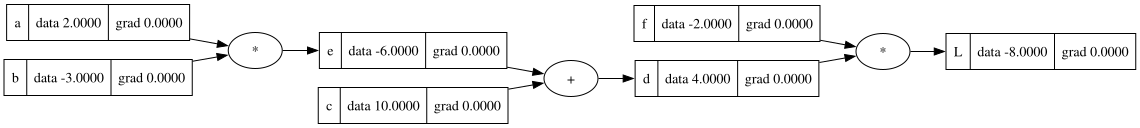

In [10]:
draw_dot(L)

In [13]:
def example():
    # inputs x1, x2
    x1 = Value(2.0, label='x1')
    x2 = Value(0.0, label='x2')
    # weights w1, w2
    w1 = Value(-3.0, label='w1')
    w2 = Value(1.0, label='w2')
    # bias of the neuron
    b = Value(6.8813735870195432, label='b')
    # # z = -3*2 + 1*0 + b = 0.8813735870195432
    # tanh(z) = 0.70710678
    # tanh'(z) = 1 - tanh(z)^2 = 0.5
    # 역전파에서 gradient 계산을 쉽게 확인하기 위한 값 

    # x1*w1 + x2*w2 + b
    x1w1 = x1 * w1; x1w1.label = 'x1*w1'
    x2w2 = x2 * w2; x2w2.label = 'x2*w2'
    x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
    n = x1w1x2w2 + b; n.label = 'n'

    # tanh activation
    o = n.tanh(); o.label = 'o'
    o.backward()
    return o

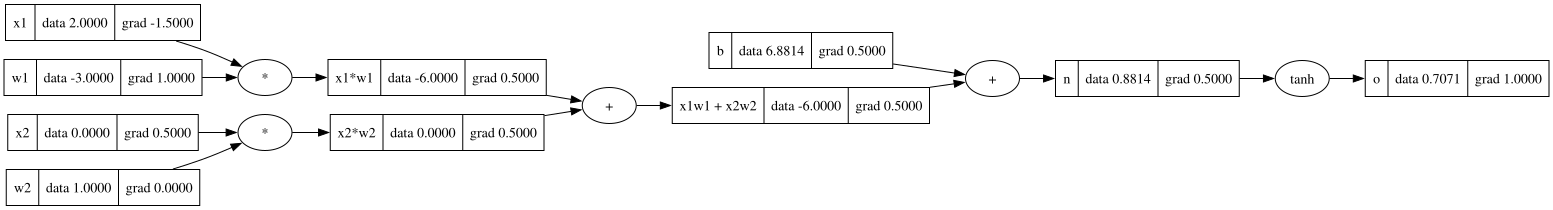

In [14]:
draw_dot(example())

In [ ]:
# tanh도 결국 수식
def example_break_up_tanh():
    # inputs x1, x2
    x1, x2 = Value(2.0, label='x1'), Value(0.0, label='x2')
    # weights w1, w2
    w1, w2 = Value(-3.0, label='w1'), Value(1.0, label='w2')
    # bias of the neuron
    b = Value(6.8813735870195432, label='b')

    # x1*w1 + x2*w2 + b
    x1w1 = x1 * w1; x1w1.label = 'x1*w1'
    x2w2 = x2 * w2; x2w2.label = 'x2*w2'
    x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
    n = x1w1x2w2 + b; n.label = 'n'

    # tanh activation
    e = (2*n).exp()
    o = (e-1) / (e+1); 
    o.label = 'o'
    o.backward()
    return o
    

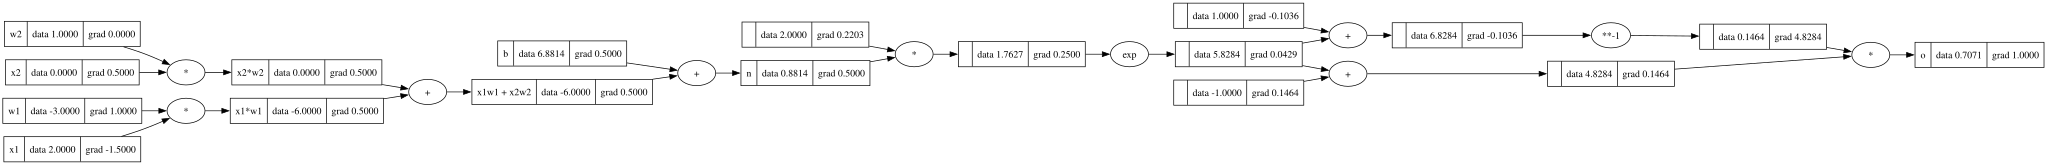

In [23]:
draw_dot(example_break_up_tanh())

In [ ]:
import torch

In [33]:
def tensor_example():
    x1 = torch.tensor([2.0], dtype=torch.float64, requires_grad=True)
    x2 = torch.tensor([0.0], dtype=torch.float64, requires_grad=True)
    w1 = torch.tensor([-3.0], dtype=torch.float64, requires_grad=True)
    w2 = torch.tensor([1.0], dtype=torch.float64, requires_grad=True)
    b = torch.tensor([6.8813735870195432], dtype=torch.float64, requires_grad=True)
    # b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True <- 이렇게 하면 정밀도 차이 약 0.00000018156 발생함
    n = x1*w1 + x2*w2 + b
    o = torch.tanh(n)

    print(o.data.item())
    o.backward()

    print('---')
    print('x2', x2.grad.item())
    print('w2', w2.grad.item())
    print('x1', x1.grad.item())
    print('w1', w1.grad.item())

    return o

tensor_example()

0.7071067811865476
---
x2 0.49999999999999994
w2 0.0
x1 -1.4999999999999998
w1 0.9999999999999999


tensor([0.7071], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [56]:
import random

class Neuron:
    '''
    @nin: number of inputs
    '''
    def __init__(self, nin: int):
        # initialize weights and bias randomly
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1, 1))

    def __call__(self, x: list):
        # w1*x1 + w2*x2 + ... + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()  # 이거는 마지막 연산에서만 사용되면 되는거아닌가? 모든 연산에서는 필요없지않나?
        return out

class Layer:
    '''
    @nin: number of inputs
    @nout: number of outputs
    '''
    # nout개의 뉴런을 생성하고, 각 뉴런은 nin개의 입력을 받는다.
    def __init__(self, nin: int, nout: int):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x: list):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs

class MLP:
    '''
    @nin: number of inputs
    @nouts: list of number of outputs for each layer
    '''
    def __init__(self, nin: int, nouts: list):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

    def __call__(self, x: list):
        for layer in self.layers:
            x = layer(x)
        return x




Value(data=-0.9827685070156359, grad=0.0)
[Value(data=0.28001771062101793, grad=0.0), Value(data=0.5496529690913998, grad=0.0), Value(data=-0.8895792310210987, grad=0.0)]


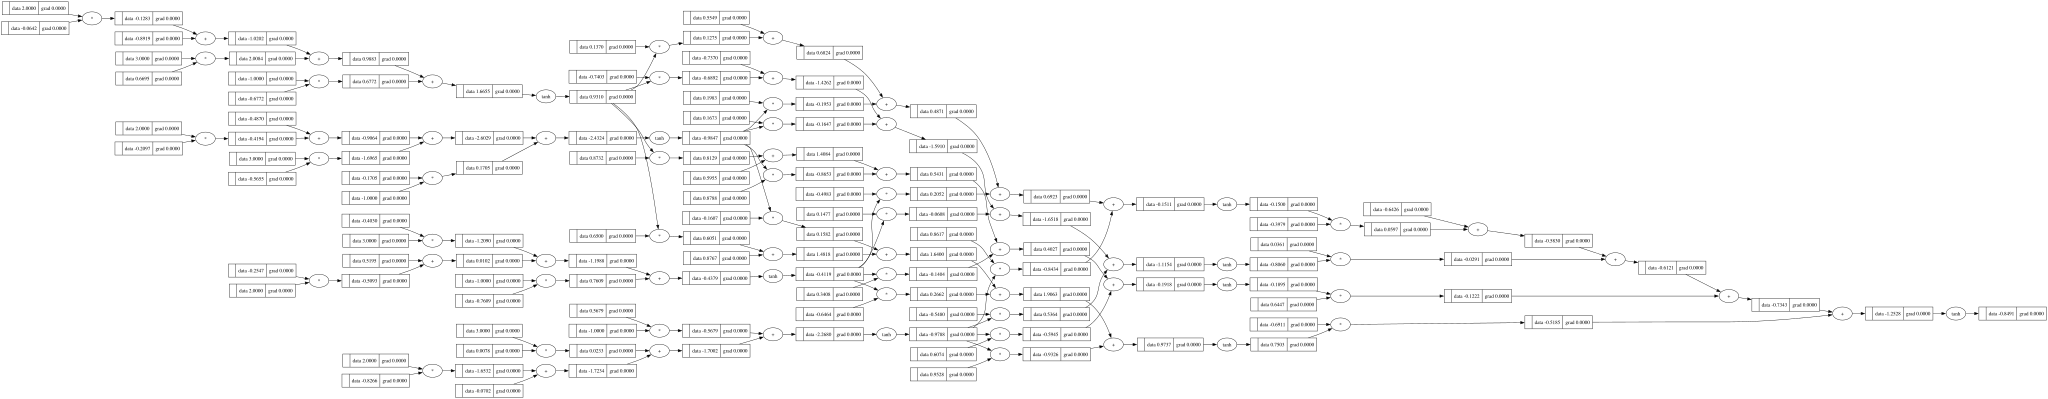

In [57]:
def runNeuron():
    x = [2.0, 3.0]
    n = Neuron(2)
    out = n(x)
    return out

def runLayer():
    l = Layer(2, 3)
    x = [2.0, 3.0]
    out = l(x)
    return out

def runMLP():
    # 3개의 입력을 받아서, 4개의 뉴런을 가진 첫번째 레이어, 4개의 뉴런을 가진 두번째 레이어, 1개의 뉴런을 가진 세번째 레이어를 가진 MLP를 생성
    n = MLP(3, [4, 4, 1])
    x = [2.0, 3.0, -1.0]
    return n(x)
    

print(runNeuron())
print(runLayer())
draw_dot(runMLP())